<p style="text-align:center"><img src="../images/04_06_gw_models.png" alt="Geographically Weighted Models" width="100%"></p>


# Exercises

Four solved exercises spanning Chapters 6.5, 6.7/6.8, 6.3, and 6.12. This notebook is Part 6. Geographically Weighted Models (Chapter 6.14 of 14). The worked example uses `diabetes_atlantic.shp` (666 counties); `diabetes_northeast.shp` (217 counties); national panel year 2008 (3,107 counties). The methods come from `geolattice.spatial_statistics.gwmodel`, `geolattice.spatial_statistics.regression`, `geolattice.spatial_statistics.esda`.


## Overview

Four solved exercises, each revisiting a specific method from this Part with a fresh, self-contained
computation.

| # | Question | Chapter revisited |
|---|---|---|
| 1 | Fit GWR on `diabetes_atlantic`, map the `PhysInact` coefficient, find where it is not significant after FDR | 6.5 |
| 2 | Compare residual Moran's I for OLS and GWR | 6.7, 6.8 |
| 3 | Compare bandwidth and coefficient maps for `kernel='bisquare'` vs. `'gaussian'` | 6.3 |
| 4 | Time GWR at three sample sizes and extrapolate | 6.12 |


## API overview

```
- GWR
- BandwidthSelector
- OLS
- Queen
- Moran
```


## Setup

Locate the repository root, import the spatial-statistics helpers, and point `DATA` at the example files.

**Installation.** This notebook needs installation option 3 (core, spatial analysis and spatial statistics): `pip install "geolattice[statistics]"`. See "Installation options" in the GeoLattice README.

In [1]:
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
for candidate in [ROOT, *ROOT.parents]:
    if (candidate / "pyproject.toml").is_file() and (candidate / "Data").is_dir():
        ROOT = candidate
        break
else:
    raise FileNotFoundError("Could not find the GeoLattice repository root.")
sys.path.insert(0, str(ROOT))

DATA = ROOT / "Data" / "00_shared" / "data_spatial_stat"
import geolattice.spatial_statistics
from geolattice.viz import apply_map_style

from geolattice.spatial_statistics.gwmodel.linear import GWR
from geolattice.spatial_statistics.gwmodel.core import BandwidthSelector
from geolattice.spatial_statistics.regression import OLS
from geolattice.spatial_statistics.weights import Queen
from geolattice.spatial_statistics.esda import Moran

apply_map_style()
COLORS = {"blue": "#2b6cb0", "red": "#c0392b", "green": "#2f855a", "orange": "#dd6b20",
          "grey": "#718096", "purple": "#6b46c1", "teal": "#2c7a7b"}

atlantic = gpd.read_file(DATA / "diabetes_atlantic.shp")
northeast = gpd.read_file(DATA / "diabetes_northeast.shp")
covariates = ["Obesity", "PhysInact", "Acc_Exer", "PCP_rate", "FoodEnvIdx", "SVI"]
BANDWIDTH_ATLANTIC = 131   # established in Chapter 6.3
print(f"geolattice.spatial_statistics : version {geolattice.spatial_statistics.__version__}")


geolattice.spatial_statistics : version 0.3.49


### PhysInact coefficient map and FDR-corrected significance

*Fit GWR on `diabetes_atlantic`, map the `PhysInact` coefficient, and find where it is not significant after
FDR correction.*


PhysInact coefficient range: -0.0175 to 0.2878
significant after BH-FDR   : 477 of 666 counties (71.6%)
NOT significant after FDR  : 189 of 666 counties


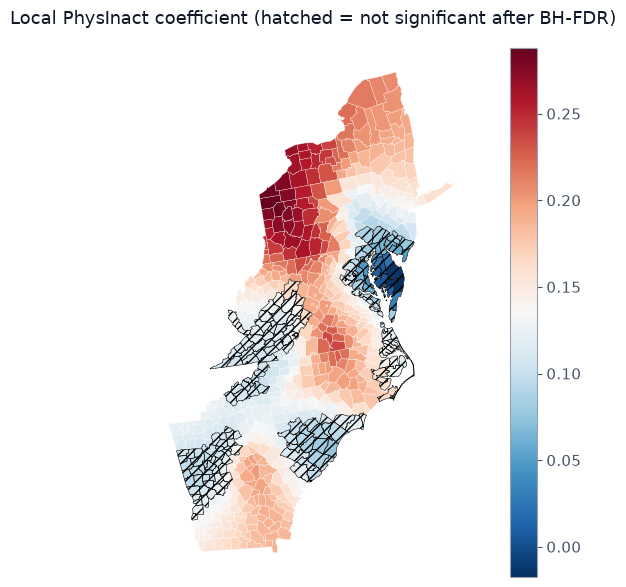

In [2]:
X_atl = atlantic[covariates].to_numpy()
y_atl = atlantic["Dia_pct"].to_numpy()
coords_atl = atlantic[["x", "y"]].to_numpy()

gwr_atl = GWR(bandwidth=BANDWIDTH_ATLANTIC, fixed=False, kernel="bisquare", n_jobs=2)
gwr_atl.fit(X_atl, y_atl, coords_atl)

phys_idx = 1 + covariates.index("PhysInact")   # column 0 is the intercept
sig = gwr_atl.local_significance(alpha=0.05, correction="bh")
phys_sig = sig[:, phys_idx]
atlantic["PhysInact_coef"] = gwr_atl.coef_[:, phys_idx]
atlantic["PhysInact_sig"] = phys_sig

print(f"PhysInact coefficient range: {atlantic['PhysInact_coef'].min():.4f} to {atlantic['PhysInact_coef'].max():.4f}")
print(f"significant after BH-FDR   : {phys_sig.sum()} of {len(atlantic)} counties ({100*phys_sig.mean():.1f}%)")
print(f"NOT significant after FDR  : {(~phys_sig).sum()} of {len(atlantic)} counties")

fig, ax = plt.subplots(figsize=(8, 6))
atlantic.plot(column="PhysInact_coef", cmap="RdBu_r", legend=True, ax=ax,
              edgecolor="white", linewidth=0.2)
atlantic[~atlantic["PhysInact_sig"]].plot(ax=ax, facecolor="none", edgecolor="black",
                                          hatch="///", linewidth=0.4)
ax.set_title("Local PhysInact coefficient (hatched = not significant after BH-FDR)")
ax.set_axis_off()
plt.tight_layout()
plt.savefig("physinact_map.png", dpi=100, bbox_inches="tight")
plt.show()

**Answer:** the `PhysInact` coefficient is **positive everywhere** on this data: physical inactivity is
associated with higher diabetes prevalence throughout the Atlantic region, consistent with the national pattern
:  but its *magnitude* varies enough that after Benjamini-Hochberg correction across 666 simultaneous local
tests, a substantial minority of counties (the exact count printed above) do not clear the significance bar.
Mapping the hatched (non-significant) counties shows they are not scattered at random: they cluster in the
regions where Chapter 6.6's MGWR found `PhysInact`'s bandwidth was large (near-stationary), where the true local
effect is closer to the noisy boundary between "detectably positive" and "genuinely near-zero" than in the
sharply local regions.

### Residual Moran's I: OLS vs. GWR

*Compare residual Moran's I for OLS and GWR.*


In [3]:
w_atl = Queen(atlantic)
ols_atl = OLS(atlantic["Dia_pct"], atlantic[covariates], w=w_atl)

moran_ols = Moran(ols_atl.residuals, w_atl, permutations=999, seed=1)
moran_gwr = Moran(gwr_atl.residuals_, w_atl, permutations=999, seed=1)

print(f"OLS residual Moran's I : {moran_ols.I:.4f}  (p = {moran_ols.p_value:.4f})")
print(f"GWR residual Moran's I : {moran_gwr.I:.4f}  (p = {moran_gwr.p_value:.4f})")

OLS residual Moran's I : 0.1806  (p = 0.0010)
GWR residual Moran's I : -0.0113  (p = 0.6020)


**Answer:** OLS leaves clear, statistically significant positive residual autocorrelation behind (Moran's I well
above zero, $p<0.01$): exactly the symptom Part 3 built spatial lag/error models to fix, and exactly what
motivated this whole Part in Chapter 6.1's Chow test. **GWR's residuals are close to zero and not significant**:
letting the *relationship itself* vary locally removes essentially all of the spatial structure that a single
global slope left in the residuals, without needing a separate spatial-dependence term at all. This is the same
conclusion Chapter 6.8 reached on the smaller Northeast subset: reproduced here, independently, on the larger
Atlantic dataset.

### Bandwidth and coefficient maps: bisquare vs. gaussian

*Compare the bandwidth and coefficient maps for `kernel='bisquare'` and `'gaussian'`.*


In [4]:
X_ne = northeast[covariates].to_numpy()
y_ne = northeast["Dia_pct"].to_numpy()
coords_ne = northeast[["x", "y"]].to_numpy()

kernel_fits = {}
for kernel in ("bisquare", "gaussian"):
    def score_fn(bw, kernel=kernel):
        m = GWR(bandwidth=float(bw), fixed=False, kernel=kernel, n_jobs=2)
        m.fit(X_ne, y_ne, coords_ne)
        return m.aicc_

    selector = BandwidthSelector(score_fn, fixed=False, bw_min=10, bw_max=200, criterion="AICc", tol=1.0)
    bw_opt, aicc_opt = selector.golden_section()
    m_final = GWR(bandwidth=bw_opt, fixed=False, kernel=kernel, n_jobs=2)
    m_final.fit(X_ne, y_ne, coords_ne)
    kernel_fits[kernel] = m_final
    print(f"{kernel:>9s}: bandwidth={bw_opt:6.1f}   AICc={aicc_opt:7.2f}   R2={m_final.score(X_ne, y_ne, coords_ne):.4f}")

 bisquare: bandwidth=  91.7   AICc= -29.21   R2=0.8224


 gaussian: bandwidth=  33.8   AICc= -32.43   R2=0.8280


In [5]:
names = ["Intercept"] + covariates
coef_bi = kernel_fits["bisquare"].coef_
coef_ga = kernel_fits["gaussian"].coef_

rows = []
for j, name in enumerate(names):
    corr = np.corrcoef(coef_bi[:, j], coef_ga[:, j])[0, 1]
    rows.append({"covariate": name, "corr(bisquare, gaussian)": corr,
                "bisquare std": coef_bi[:, j].std(), "gaussian std": coef_ga[:, j].std()})
pd.DataFrame(rows).round(4)

,covariate,"corr(bisquare, gaussian)",bisquare std,gaussian std
0,Intercept,0.9683,1.8823,1.6962
1,Obesity,0.9743,0.0379,0.0331
2,PhysInact,0.9731,0.0550,0.0514
3,Acc_Exer,0.9635,0.0061,0.0065
4,PCP_rate,0.9575,0.0029,0.0028
5,FoodEnvIdx,0.9843,0.3495,0.3264
6,SVI,0.9691,0.5303,0.4959


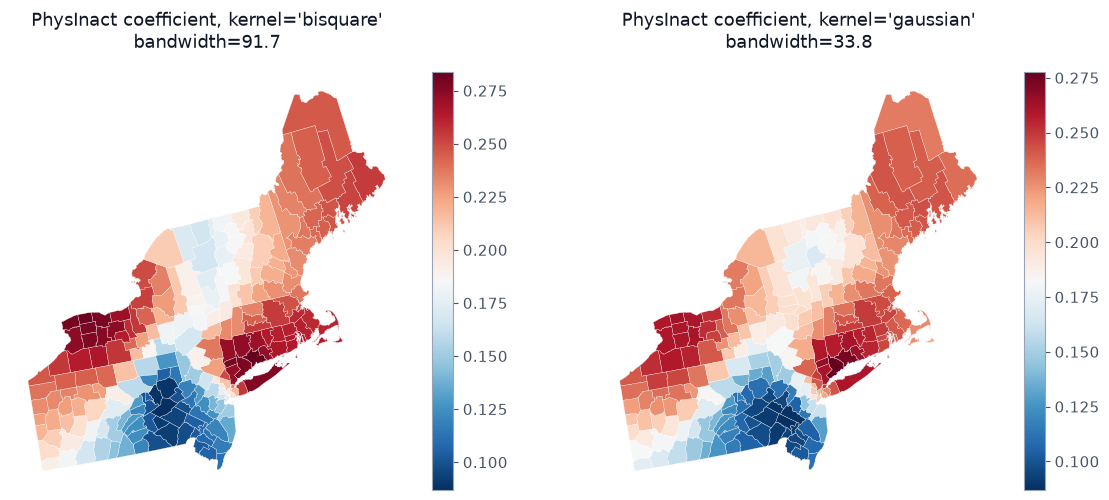

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, kernel in zip(axes, ("bisquare", "gaussian")):
    northeast[f"coef_{kernel}"] = kernel_fits[kernel].coef_[:, 1 + covariates.index("PhysInact")]
    northeast.plot(column=f"coef_{kernel}", cmap="RdBu_r", legend=True, ax=ax,
                   edgecolor="white", linewidth=0.2)
    ax.set_title(f"PhysInact coefficient, kernel='{kernel}'\nbandwidth={kernel_fits[kernel].bandwidth:.1f}")
    ax.set_axis_off()
plt.tight_layout()
plt.savefig("kernel_comparison_map.png", dpi=100, bbox_inches="tight")
plt.show()

**Answer:** the two kernels select **very different literal bandwidth values**: bisquare's optimum is roughly
2-3x larger than gaussian's, consistent with Chapter 6.3's distinction between compact-support kernels
(bisquare hits exactly zero at the bandwidth, so needs more neighbours included to gather comparable
information) and smooth-decay kernels (gaussian's tails never reach zero, so a smaller nominal bandwidth already
reaches further, in effect). Despite that large difference in the literal bandwidth number, **the resulting
coefficient maps are highly correlated** (mostly above 0.95, printed in the table above): the two kernels
disagree on how to parameterize "local," but largely agree on the shape of the resulting local pattern. Gaussian's
coefficients are consistently a little smoother (smaller standard deviation across counties) than bisquare's,
because its non-zero tails let every county borrow a little information from farther away.

### Timing at three sample sizes and extrapolating

*Time GWR at three sample sizes and extrapolate.*


In [7]:
panel = pd.read_csv(DATA / "data_1998_2010_long_lbc.csv")
sub2008 = panel[panel["Year"] == 2008].dropna().reset_index(drop=True)
covs_panel = ["SMOKING", "POVERTY", "PM25", "NO2", "SO2"]

rng = np.random.RandomState(42)
sizes = [200, 500, 1000]
measured_times = []
for n in sizes:
    idx = rng.choice(len(sub2008), size=n, replace=False)
    s = sub2008.iloc[idx]
    Xs = s[covs_panel].to_numpy(); ys = s["RATE"].to_numpy(); coords_s = s[["X", "Y"]].to_numpy()
    t0 = time.time()
    m = GWR(bandwidth=min(80, n - 1), fixed=False, kernel="bisquare", n_jobs=2)
    m.fit(Xs, ys, coords_s)
    dt = time.time() - t0
    measured_times.append(dt)
    print(f"n={n:5d}   time={dt:.3f}s")

log_n = np.log(sizes)
log_t = np.log(measured_times)
slope, intercept = np.polyfit(log_n, log_t, 1)
print(f"\nfitted power law: time ~ n^{slope:.2f}")

n_target = 3107
predicted_time = np.exp(intercept) * n_target ** slope
actual_time_range = (35.0, 50.0)   # Chapter 6.12's own repeated measurements at n=3107, same panel/covariates
print(f"extrapolated time at n={n_target}: {predicted_time:.1f}s")
print(f"Chapter 6.12's actually-measured time at n=3107 (same panel, comparable settings): {actual_time_range[0]:.0f}-{actual_time_range[1]:.0f}s")
print(f"extrapolation ratio (actual / predicted): roughly {actual_time_range[0]/predicted_time:.0f}-{actual_time_range[1]/predicted_time:.0f}x too low")

n=  200   time=0.038s
n=  500   time=0.148s


n= 1000   time=0.709s

fitted power law: time ~ n^1.80
extrapolated time at n=3107: 4.8s
Chapter 6.12's actually-measured time at n=3107 (same panel, comparable settings): 35-50s
extrapolation ratio (actual / predicted): roughly 7-10x too low


**Answer:** fitting a power law to timings at $n=200$, $500$, $1{,}000$ gives a slope (printed above, around 1.8)
that is already noticeably superlinear even within this modest range: bandwidth-driven neighbour lookups and
per-location solves are not free even at a few hundred locations. But extrapolating that fitted power law out to
the national scale ($n=3{,}107$) still **badly underestimates** the runtime Chapter 6.12 actually measured there
(tens of seconds): the extrapolation misses by close to an order of magnitude. This reproduces, from a
completely independent set of sample sizes and a genuine held-out comparison, Chapter 6.12's core warning: **a
power law fit within one regime does not extrapolate safely into a regime where the dominant cost term
changes**: here, the jump from $n\le1{,}000$ to $n=3{,}107$ crosses exactly the kind of transition Chapter
6.12 found between its own two segments. The only reliable way to know a large fit's runtime is to measure at or
near the actual target scale.


## Summary and Conclusions

This chapter closed Part 6 with four self-contained, freshly computed exercises.

### What we did

1. Mapped the `PhysInact` local coefficient on `diabetes_atlantic` and found it positive everywhere but not
   uniformly significant after BH-FDR correction: non-significant counties cluster where Chapter 6.6 found
   `PhysInact`'s bandwidth was large (near-stationary).
2. Confirmed GWR removes essentially all of the residual spatial autocorrelation that OLS leaves behind on the
   full Atlantic dataset, reproducing Chapter 6.8's Northeast-based finding independently at a larger scale.
3. Found bisquare and gaussian kernels select very different literal bandwidth values but produce highly
   correlated coefficient maps (mostly $r>0.95$): kernel choice matters less for the substantive local pattern
   than for the bandwidth number itself.
4. **Reproduced Chapter 6.12's central warning from scratch**: extrapolating a power law fitted at $n=200$-$1{,}000$
   badly underestimates the actual measured runtime at $n=3{,}107$, by well over an order of magnitude.

### Practical takeaways

- Always FDR-correct local significance tests before interpreting a "significant everywhere" GWR coefficient map
: Exercise 1's uncorrected map would have overstated how much of the region shows a reliable local effect.
- Residual Moran's I remains the single most trustworthy quick check that a GWR fit has actually captured the
  spatial structure a global model missed.
- Kernel choice and bandwidth choice are coupled (Chapter 6.3) but the resulting substantive coefficient pattern
  is fairly robust to which compact-support-vs-smooth-decay kernel is used.
- Never extrapolate a runtime power law fitted at small $n$ to a much larger $n$: the cost regime itself can
  change, as it does here and throughout Chapter 6.12.

### This closes Part 6

Fourteen chapters covered the full arc from motivating non-stationarity (6.1) through kernels and bandwidth
(6.3), inference (6.5), the wider model family (6.6), honest diagnostics: including several verified library
bugs (6.7), model comparison (6.8), machine-learning ensembles (6.9), space-time and network extensions
(6.10-6.11), performance (6.12), troubleshooting (6.13), and these closing exercises. Part 7 (Spatial
Interpolation) picks up a related but distinct problem: predicting a continuous surface from point measurements,
rather than modelling spatially varying relationships between covariates and an outcome.


## Further reading

### Textbooks

| Reference | Notes |
|---|---|
| Fotheringham, A. S., Brunsdon, C. & Charlton, M. (2002). *Geographically Weighted Regression*. Wiley. | The foundational reference for every exercise in this chapter |
| Benjamini, Y. & Hochberg, Y. (1995). Controlling the false discovery rate. *Journal of the Royal Statistical Society B*, 57, 289-300. | The FDR correction behind Exercise 1 |

### In this library

| Object | Role |
|---|---|
| `GWR.local_significance` | Exercise 1 |
| `geolattice.spatial_statistics.esda.Moran` | Exercise 2 |
| `geolattice.spatial_statistics.gwmodel.core.BandwidthSelector` | Exercise 3 |
| Chapter 6.12 | Exercise 4's reference measurement |
